# Final project for HDEq Skills: 
`Due: Wednesday 3rd December 2025 @ 12:00 (noon)`

**Nina Beadnell, s2528247**

## Instruction and marking scheme

Your submission (like your assignments) will be a Jupyter Notebook (.ipynb file).  For your analysis and discussion use Markdown cells instead of comments in the code.

For the presentation and coding style:
- The plots should be in a good size, properly labelled and markers/lines wisely chosen. It might be a good idea to combine some plots and put several curves together for easier comparison and conciseness. 
- Your code should be well commented with meaningful variable names and good structures. You don't need to over comment it though!
- The writing should be clear and concise with minimal language or typing mistakes.


It is important that you think about good academic practice when you construct your answers. The work you submit must reflect **your own understanding**, in line with the School's policy on academic misconduct: https://teaching.maths.ed.ac.uk/undergraduate/studies/assessment/academic-misconduct and no generative AI is permitted. Any form of plagiarism or AI use that is detected by the software or markers will be reported to the school for the due process.

## Part 1: Wave equation with linear damping

Consider the following wave equation that includes a damping term


\begin{equation}
u_{tt} + \nu u_{t} = c^2 u_{xx}
\end{equation}

with the boundary conditions
\begin{equation}
u\left(x = 0, t\right) = 0 , \quad u\left(x = L, t\right) = 0,
\end{equation}
and the initial conditions
\begin{equation*}
u\left(x, t=0\right) = f(x) = \exp\left(\sin^2\left(\frac{2\pi x}{L}\right)\right)-1 , \quad u_t\left(x, t=0\right) = 0,
\end{equation*}

For this problem, let's set $L=20$, $\nu = 0.2$ and $c = 1$.

We use a method to solve this PDE that is known as "Galerkin". In so doing, we approximate the solution with

\begin{equation*}
u(x, t) \approx \sum_{n=1}^{N} f_n(t) \sin(\lambda_n x) 
\end{equation*}

and then derive an appropriate ODE for $f_n(t)$ to solve numerically. This is a form of separation of variables in which the equations for the functions of time are solved numerically rather than by hand. It can be shown that when $N \to \infty$ the above series converges to the exact solution. 

🚩 **Task 1.1 (1 mark)** Considering the above form of solution, find $\lambda_n$ in terms of $n$ and $L$. 

🚩 **Task 1.2 (1 mark)** Using the assumed form of solution and PDE, find an ODE that describes the evolution of $f_n(t)$ in time, (where $n = 1, 2, \dots, N $).

🚩 **Task 1.3 (2 marks)** Using the initial conditions of the PDE and your knowledge of Fourier series, find two initial conditions for $f_n$ and $\cfrac{df_n}{dt}$ at $t=0$. Your answer in this part might in the form of an integral, which you should not evaluate at this point (we will calculate this integral later numerically).

---------------
**Task 1.1** 


From course notes, we have that Fourier Sine series yeilds eigenvalues $\lambda_n=\frac{n\pi}{L}$. 


Within the context of this question $L = 20$ so our approximate solution can be given as,
\begin{equation*}
u(x, t) \approx \sum_{n=1}^{N} f_n(t) \sin\left(\frac{n\pi}{20} x\right).
\end{equation*}


**Task 1.2** 


Using the assumed form of the solution $u(x, t) \approx \sum_{n=1}^{N} f_n(t) \sin(\lambda_n x)$ we can generate the following,
\begin{equation}
u_{tt} \approx \sum_{n=1}^{N} f''_n(t) \sin(\lambda_n x), \quad   u_{t} \approx \sum_{n=1}^{N} f'_n(t) \sin(\lambda_n x), \quad   u_{xx} \approx \sum_{n=1}^{N} f_n(t) \left({-\lambda_n^{2}}\right)\sin(\lambda_n x).
\end{equation}


We can then used the PDE wave equation $u_{tt} + \nu u_{t} = c^2 u_{xx}$ getting
\begin{equation}
u_{tt} + \nu u_{t} - c^2 u_{xx} \approx \sum_{n=1}^{N} f''_n(t) \sin(\lambda_n x)+\nu \sum_{n=1}^{N} f'_n(t) \sin(\lambda_n x)-c^2\sum_{n=1}^{N} f_n(t) \left({-\lambda_n^{2}}\right)\sin(\lambda_n x) 
\\
\implies \sum_{n=1}^{N} \left(f''_n(t) \sin(\lambda_n x) + \nu f'_n(t) \sin(\lambda_n x)+c^2\lambda_n^{2}f_n(t) \sin(\lambda_n x)\right)=0
\\
\implies \sum_{n=1}^{N} \sin(\lambda_n x)\left(f''_n(t) + \nu f'_n(t)+c^2\lambda_n^{2}f_n(t)\right)=0
\\
\end{equation}

Since we have that Fourier sine serier have orthogonality we can then extract the ODE that describes the evolution of $f_n(x)$ in time, where $n=1,...,N$, is



\begin{equation}
f''_n(t) + \nu f'_n(t) + c^2\lambda_n^{2} f_n(t)=0
\end{equation}


**Task 1.3**


Using the wave PDE and initial conditions, we have
\begin{equation}
u\left(x, t=0\right) = f(x) = \exp\left(\sin^2\left(\frac{2\pi x}{L}\right)\right)-1 \approx\sum_{n=1}^{N} f_n{(0)}\sin(\lambda_n x) \quad \text{ and } \quad u_t\left(x, t=0\right)=0\approx\sum_{n=1}^{N} f^{'}_n{(0)}\sin(\lambda_n x)
\end{equation}

Begining with the first initial condition, we can determine an expression for $f_n$ by multiplying through by $\sin{\lambda_m x}$ and integrating termwise from $L$ to $-L$ as follows, 
\begin{equation}
\int^L_{-L}{f(x)\sin(\lambda_n x)}dx \approx\sum_{n=1}^{N} f_n{(0)}\int^L_{-L}{\sin(\lambda_m x)\sin(\lambda_n x)}dx,
\end{equation}

then using orthogonality relations,
\begin{equation}
\int^L_{-L}{f(x)\sin(\lambda_n x)} \approx\sum_{n=1}^{N} f_n{(0)}.
\end{equation}

We can then extract the expression for $f_n$ using knowledge of the Euler-Fourier formulas. Hence,
\begin{equation}
f_n{(0)}\approx \frac{2}{L}\int^L_{0}{f(x)\sin(\lambda_n x)} = \frac{2}{L}\int^L_{0}{\left(\exp\left(\sin^2\left(\frac{2\pi x}{L}\right)\right)-1\right)\sin(\lambda_n x)}.
\end{equation}

Similarly for the second initial condidtion we get,

\begin{equation}
0 \approx \sum_{n=1}^{N} f^{'}_n{(0)}\int^L_{-L}{\sin(\lambda_m x)\sin(\lambda_n x)}dx \implies \frac{df_n}{dt}(0)\approx 0.
\end{equation}


--------------

🚩 **Task 1.4 (3 marks)** Write a function that takes $n$ (the index of the terms in the series solution, for example $n=3$ corresponds to $f_3(0)$) as an input and returns $f_n(0)$. You might solve this part using different tools: 1) `sympy` module or 2) direct numerical calculation using  `scipy.integrate` (see the documentation [here](https://docs.scipy.org/doc/scipy/reference/tutorial/integrate.html)). Make sure your final result is a numerical real value (not symbolic expressions). Remember from your labs that you can use `.N()` method to evaluate a sympy expression (if you decide to use `sympy`, which is not the only way to complete this task).

Once you have written your function, use it to calculate $f_n(0)$ for $L=20$, $n=7$ and the given initial condition $u(x, t=0) = \exp\left(\sin^2\left(\frac{2\pi x}{L}\right)\right)-1$.

In [1]:
# Task 1.4

import sympy as sym
import numpy as np
sym.init_printing()
from IPython.display import display_latex
from IPython.display import Latex, display

x,L = sym.symbols('x, L')

# Using initial condition u(t,0) = f(x)
def integrand(x):
    return sym.exp(sym.sin((2 * sym.pi * x) / L) ** 2) - 1
    
def calc_fn_0(k):
    '''
    Inputs:
    -------
    k - Index of terms in the series solution corresponding to f_k(0)
    
    Outputs:
    --------
    f_k(0) - Series solution to the kth term at x=0
    
    '''
    # Evaluating the integral derived in Task 1.3 wirth respect to x, from 0 to L
    integral = (2 / L) * sym.Integral(integrand(x) * sym.sin((sym.pi * x * k) / L), (x, 0, L))

    return integral


# Test code
L = 20
display(Latex(r"Value for $f_{7}(0)$ is:"))
display_latex(calc_fn_0(7).evalf())

<IPython.core.display.Latex object>

🚩 **Task 1.5 (4 marks)** Write a function to solve the ODEs that you derived in 'Task 1.2' for each $f_n(t)$. Your function takes $n$ (the index of terms in the solution series) and `t_vec` (the vector of times at which you want to have the solution). Then, it calculates the corresponding initial conditions ($f_n$ and $\cfrac{df}{dt}$ at $t=0$), solves the associated ODE and returns the solution at each point in `t_vec`. Use `odeint` to solve the ODE numerically. You may also use the function you wrote in the previous task.

Use the function to plot $f_1(t)$, $f_2(t)$ and $f_3(t)$ for `t_vec = np.linspace(0, 100, 1001)`.

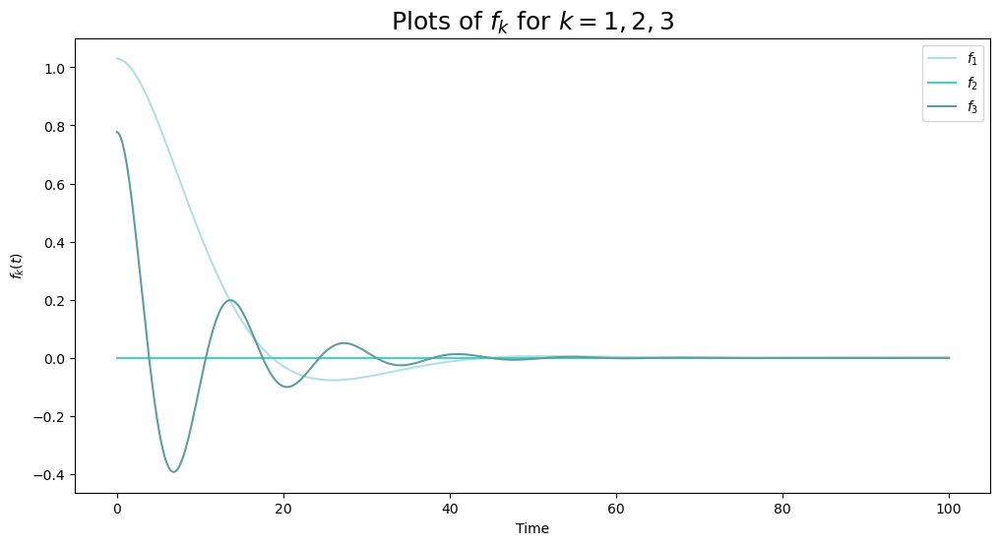

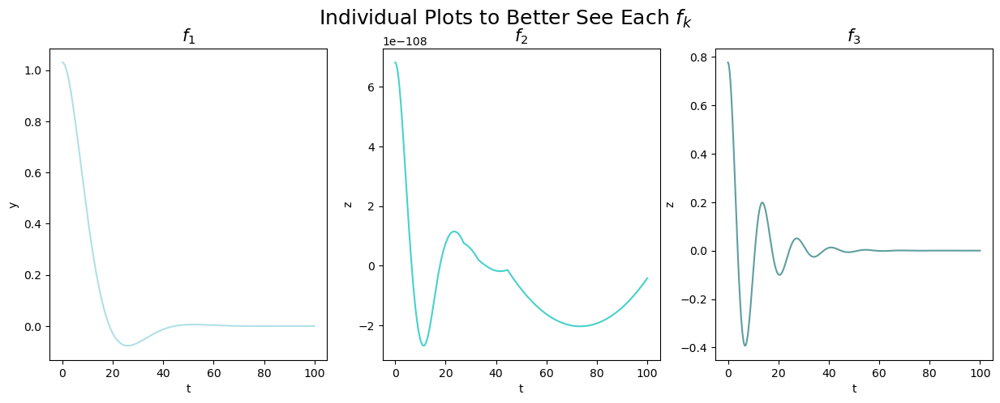

In [2]:
# Task 1.5

import matplotlib.pyplot as plt
from scipy.integrate import odeint
# and this is the line in case the figure does not show up!
%matplotlib inline

# Variables
nu = .2
c = 1
L = 20 

# Defining our ODE
def dF_dt(F, t, k):
    '''
    This function defines the RHS of the system of ODEs for f_n's
    -------------------------------------------------------------
    '''
    # Equation from Task 1.2 
    # To simplify our 2nd order ODE, transform it into a system of 1st order ODEs
    a1, a2 = F
    eq = [a2, - nu * a2 - (c ** 2) * ((np.pi** 2) * (k ** 2))  / (L ** 2) * a1]
    
    return eq
    
# Solving ODE     
def fn_solve(k, t_vec):
    '''
    This function derives the solution of f_k(t) for all the times in 't_vec'
    'k' is given as an input and marks the index of the term in series solution 
    ---------------------------------------------------------------------------
    Inputs:
    -------
    k - Index of terms in solution series
    t_vec - The vector of times at which you want to have the solution
    
    Outputs:
    --------
    Solution of f_k(t) for all points in t_vec
    '''
    # Initial condition using funtion in Task 1.4
    ic = [sym.N(calc_fn_0(k).evalf()),0]
    
    # Using odient to numerically solve with times in t_vec
    sol = odeint(dF_dt, ic, t_vec, args = (k,))
    
    return sol
    
# Plots

# Times
t_vec = np.linspace(0, 100, 1001)

# Formatting colours
colours = ["powderblue", "mediumturquoise", "cadetblue"]

# Plotting for values of k = 1, 2, 3
plt.figure(figsize=(12,6))
for k in range(1, 4, 1):
    f1_test = fn_solve(k, t_vec)
    # Plot the first column of f1_test, corresponfing to f, against time
    plt.plot(t_vec, f1_test[:,0], label = f"$f_{k}$", color = colours[k - 1])
plt.legend(loc='best')
plt.title('Plots of $f_k$ for $k = 1, 2, 3$', fontsize = 18)
plt.xlabel('Time')
plt.ylabel(r'$f_k(t)$')
plt.show()

# Plotting the solution as three seperate graphs
fig, axs = plt.subplots(1, 3, figsize=(15,5))
fig.suptitle('Individual Plots to Better See Each $f_k$', fontsize = 18)

f1_test = fn_solve(1, t_vec)
axs[0].plot(t_vec, f1_test[:,0], "powderblue")
axs[0].set_title('$f_1$', fontsize = 15)
axs[0].set(xlabel='t', ylabel='y')

f2_test = fn_solve(2, t_vec)
axs[1].plot(t_vec, f2_test[:,0], "mediumturquoise")
axs[1].set_title('$f_2$', fontsize = 15)
axs[1].set(xlabel='t', ylabel='z')

f3_test = fn_solve(3, t_vec)
axs[2].plot(t_vec, f3_test[:,0], "cadetblue")
axs[2].set_title('$f_3$', fontsize = 15)
axs[2].set(xlabel='t', ylabel='z');

🚩 **Task 1.6 (4 marks)** Write a function that takes $N$ (the total number of terms in the sine series of the solution), `t_vec` and `x_vec` (which is the vector of points in space) as inputs and returns the solution $u(x,t)$ of the PDE at the times `t_vec` and points `x_vec`. Your function output should be a $N_T \times N_X$ numpy array, where $N_T$ is the number of points in time (i.e. the size of `t_vec`) and  $N_X$ is the number of points in space (i.e. the size of `x_vec`). Make good use of the functions you already wrote in the previous tasks.

With this function, find the solution for 

`x_vec = np.linspace(0, L, 201)`

`t_vec = np.linspace(0, 100, 1001)` 

`N =7`

Make an animation to show how $u(x,t)$ changes in time (each frame of animation is the solution at all spatial points but for one specific point in time)

In [3]:
# Task 1.6

# Solving u(t,x)
def waveq_dam_solve(N, t_vec, x_vec):
    '''
    Inputs :
    --------
    N - Total number of terms in the sine series of the solution
    t_vec - Vector of points for t variable
    x_vec - Vector of points for x variable
    
    Outputs :
    ---------
    solution u(t,x) - A |t_vec| x |x_vec| function array
    
    '''
    # Define an array of the desired dimention |x_vec| x |t_vec|
    sol = np.zeros((len(t_vec), len(x_vec)))                  
    # Range over these equation from f and for t
    for p in range(1, N+1):
                   
                      
        # f_n(t) term using function from Task 1.5
        fp = fn_solve(p, t_vec)
        
        # sin(𝜆_𝑛𝑥) term
        xp = np.sin((np.pi * x_vec * p) / L)
        
        # Summing their product over all N
        sol += np.outer(fp[:,0], xp)
        
    return sol
    
# Test code
x_vec = np.linspace(0, L, 201)
t_vec = np.linspace(0, 100, 1001)
N = 7
u_x_t = waveq_dam_solve(N, t_vec, x_vec)

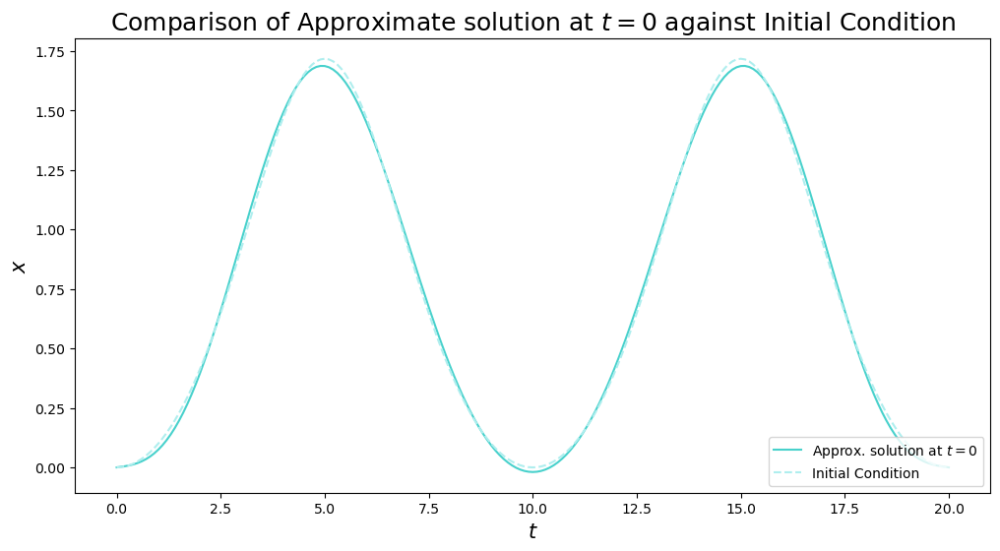

In [4]:
# Assuming the PDE's solution is stored in u_x_t[:,:],
# Compare the approx. solution at t=0 with the initial condition

# Plot
plt.figure(figsize=(12,6))
plt.plot(x_vec, u_x_t[0,:], label=r'Approx. solution at $t=0$', color='mediumturquoise')
plt.plot(x_vec,np.exp((np.sin(2*np.pi*x_vec/L))**2)-1, label='Initial Condition', color='paleturquoise', linestyle='--')
plt.legend(loc='lower right')
plt.title('Comparison of Approximate solution at $t=0$ against Initial Condition', fontsize = 18)
plt.xlabel(r'$t$', fontsize = 15)
plt.ylabel(r'$x$', fontsize = 15)
plt.show()

In [5]:
import matplotlib.animation as animation
from IPython.display import HTML

# Assuming the PDE's solution is stored in u_x_t[:,:],
# Compare the approx. solution at t=0 with the initial condition

# Maintaining nu variable for this animation (as it changes later on)
nu = .2

# Frames per second
fps = 1

# Plotting the original function
fig, ax = plt.subplots()
line, = ax.plot(x_vec, u_x_t[0,:], "mediumturquoise", label = r'Approx. solution at $t=0$')
plt.plot(x_vec, u_x_t[0,:], "paleturquoise", linestyle = '--', label = 'Initial Condition')
plt.title(r'How $u(t,x)$ Changes in Time', fontsize = 18)
plt.legend()
ax.set_xlabel("t", fontsize = 15)
ax.set_ylabel("u(t,x)", fontsize = 15)
ax.set_ylim(-0.5, 2)
plt.close()

# Add an annotation showing the time (this will be updated in each frame)
txt = ax.text(0, 0.9, 't=0')

# Defining the background of each frame
def init():
    line.set_ydata(t_vec)
    txt.set_text("t=0")
    return line, txt

def animate(i):
    line.set_ydata(u_x_t[i]/fps)  # update the data
    txt.set_text('t='+str(i/fps)) # update the annotation
    return line, txt

ani = animation.FuncAnimation(fig, animate, np.arange(0, fps*101), init_func=init,
                              interval=100, blit=True, repeat=True)

HTML(ani.to_jshtml())

🚩 **Task 1.7 (2 marks)** Examine how the solution changes for different values of $N$. Consider $N=3$, $N=7$ and $N=11$. Show the animation of the solution for all the three cases in one plot and compare them with each other. Discuss and analyse your results (for example, are three terms enough to get an acceptable solution? What about seven?)

In [6]:
# Task 1.7

# Maintaining nu variable for this animation (as it changes later on)
nu = .2

# Defining equations for N = 3, 7, 11
u_x_t_3 = waveq_dam_solve(3, t_vec, x_vec)
u_x_t_7 = waveq_dam_solve(7, t_vec, x_vec)
u_x_t_11 = waveq_dam_solve(11, t_vec, x_vec)


fig_2, ax = plt.subplots()
line3, = ax.plot(x_vec, u_x_t_3[0,:], "powderblue", label = r'$N=3$')
line7, = ax.plot(x_vec, u_x_t_7[0,:], "mediumturquoise", label = r'$N=7$')
line11, = ax.plot(x_vec, u_x_t_11[0,:], "cadetblue", label = r'$N=11$')
plt.plot(x_vec, u_x_t[0,:], "paleturquoise", linestyle = '--', label = 'Initial Condition')
plt.title(r'How $u(t,x)$ Changes in Time', fontsize = 18)
ax.set_xlabel("t", fontsize = 15)
ax.set_ylabel("u(t,x)", fontsize = 15)
ax.set_ylim(-0.5, 2)
ax.legend()
plt.close()

def init_2():
    line3.set_ydata(u_x_t_3[0,:])
    line7.set_ydata(u_x_t_7[0,:])
    line11.set_ydata(u_x_t_11[0,:])
    return line3, line7, line11,

# Add an annotation showing the time (this will be updated in each frame)
txt = ax.text(0, 0.9, 't=0')
    
def animate_2(i):
    line3.set_ydata(u_x_t_3[i,:]/fps)
    line7.set_ydata(u_x_t_7[i,:]/fps)
    line11.set_ydata(u_x_t_11[i,:]/fps)
    txt.set_text('t='+str(i/fps)) # update the annotation
    return line3, line7, line11, txt

    
ani_2 = animation.FuncAnimation(fig_2, animate_2, np.arange(0, fps*101), init_func=init_2,
                                  interval=100, blit=True, repeat=True)

HTML(ani_2.to_jshtml())

🚩 **Task 1.8 (1 marks)** Change the damping parameter to $\nu = 2$, and repeat the 'task 1.6' (for $N=7$ and keep all other parameters the same). In few sentences, explain the changes caused by increasing the damping.

In [7]:
# Task 1.8

# Changing nu variable
nu = 2 

x_vec = np.linspace(0, L, 201)
t_vec = np.linspace(0, 100, 1001)
N = 7
u_x_t_nu = waveq_dam_solve(N, t_vec, x_vec)

# Animation as in Task 1.6

# Frames per second
fps = 1

# Plotting the original function
fig_3, ax = plt.subplots()
line, = ax.plot(x_vec, u_x_t_nu[0,:], "mediumturquoise")
plt.plot(x_vec, u_x_t_nu[0,:], "paleturquoise", linestyle = '--', label = 'Initial Condition')
plt.title(r'How $u(t,x)$ Changes in Time', fontsize = 18)
ax.set_xlabel("t", fontsize = 15)
ax.set_ylabel("u(t,x)", fontsize = 15)
ax.set_ylim(-0.5, 2)
plt.close()

# Add an annotation showing the time (this will be updated in each frame)
txt = ax.text(0, 0.9, 't=0')

# Defining the background of each frame
def init_3():
    line.set_ydata(t_vec)
    txt.set_text("t=0")
    return line, txt

def animate_3(i):
    line.set_ydata(u_x_t_nu[i]/fps)  # update the data
    txt.set_text('t='+str(i/fps)) # update the annotation
    return line, txt

ani_3 = animation.FuncAnimation(fig_3, animate_3, np.arange(0, fps*101), init_func = init_3,
                              interval = 100, blit=True, repeat=True)

HTML(ani_3.to_jshtml())

**Explain the changes caused by increasing the damping**



In this animation we have $\nu=2$ which is a larger value that we modelled with prevously, with $\nu=0.2$. This increase in $\nu$ leads to increased dampening effect as our wave equation $u_{tt} + \nu u_{t} = c^2 u_{xx}$ is now accomodating more resistance with respect to the velocity term $u_t$.


--------------

## Part 2: Lorenz system


The Lorenz system is given by the coupled set of ODEs
\begin{equation}
  \frac{\mathrm{d}x}{\mathrm{d}t} = -\sigma x + \sigma y, \qquad
  \frac{\mathrm{d}y}{\mathrm{d}t} = x(\rho - z) - y, \qquad
  \frac{\mathrm{d}z}{\mathrm{d}t} = xy - \beta z,
\end{equation}
where ($\rho, \sigma, \beta$) are system parameters. Lorenz derived these equation as a simplified mathematical model for [atmospheric convection](https://en.wikipedia.org/wiki/Atmospheric_convection), which is an aspect of weather.  While the Lorenz system is deterministic, you will find in this problem that in certain sets of parameters there is sensitive dependence of the solution on the initial condition. Assuming this system is a representation of weather, small errors invariably arise (e.g. numerical discretisation, measurements inaccuracy), grow and affect long term solutions (cf. loss of predictability in weather forecasting). However, there are statistical properties (cf. the climatology) that may be robust and may be described accordingly.

--------------------
### Case of stable solution


Consider the parameters $\sigma = 10$, $\beta = 3$ and $\rho = 12$.


🚩 **Task 2.1 (1 mark)** Find all the critical points of this system.

🚩 **Task 2.2 (2 marks)** Using a numerical method of your choice, find the solution starting from $x(t=0) = y(t=0) = z(t=0) = 10$ up to $t=20$. Plot the solution in *x-y*, *y-z* and *x-z* planes (so you need three plots). Where does this initial condition end up in? Can you express the exact location of this solution as $t \to \infty$? Make sure your timestep is small enough to have robust results. You can check this by running your code for several different timesteps.

--------
**Task 2.1** Given the parameters $\sigma = 10$, $\beta = 3$ and $\rho = 12$, we can rewrite the Lorenz system as


\begin{equation}
  \frac{\mathrm{d}x}{\mathrm{d}t} = -10 x + 10 y, \qquad
  \frac{\mathrm{d}y}{\mathrm{d}t} = x(12 - z) - y, \qquad
  \frac{\mathrm{d}z}{\mathrm{d}t} = xy - 3 z,
\end{equation}


the critical points arise when $\frac{\mathrm{d}x}{\mathrm{d}t}=\frac{\mathrm{d}y}{\mathrm{d}t}=\frac{\mathrm{d}z}{\mathrm{d}t}=0$. We then have a system of 3 equations and can solve for $x,y$ and $z$.


\begin{align}
    \frac{\mathrm{d}x}{\mathrm{d}t}=0=&-10x+10y \\
    \implies& x=y \\
\end{align}


Then,
\begin{align}
\frac{\mathrm{d}y}{\mathrm{d}t}= 0 = & x (12-z)-y \quad \text{ using  $x=y$}\\
\implies& 0=12x-xz-x \\
\implies& 0=x(11-z) \\
\end{align}


If $x=0 \implies y=0$, and if $11-z=0 \implies z=11$.


Then, 
\begin{align}
\frac{\mathrm{d}z}{\mathrm{d}t}=0=&xy-3z \quad \text{ using  $x=y$}\\
\implies& 0=x^2-3z \\
\implies& x=\pm \sqrt{3z} 
\end{align}


Hence critical point occur at $(0,0,0), \left(\sqrt{33},\sqrt{33},11\right)$ and $\left(-\sqrt{33},-\sqrt{33},11\right)$.



-----------

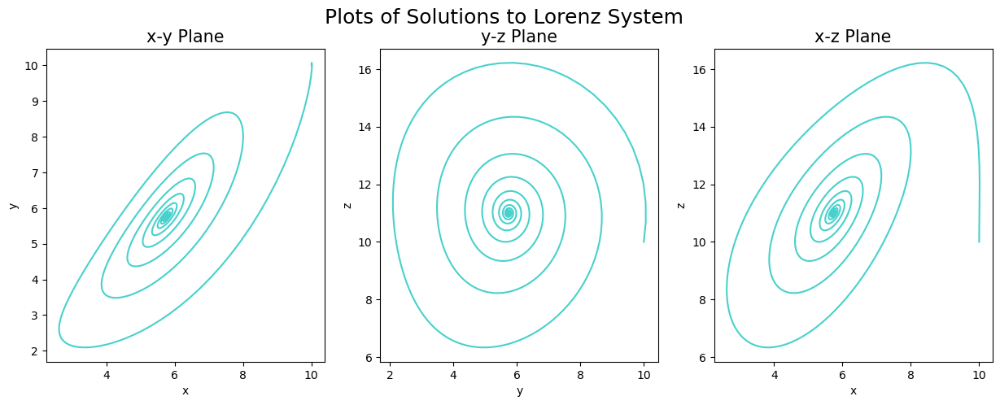

In [8]:
# Task 2.2


# Chosen numerical method - Heun scheme taken from Lab 2
def ode_Heun(func, times, y0):
    '''
    integrates the system of y' = func(y, t) using Heun's method
    for the time steps in times and given initial condition y0
    ----------------------------------------------------------
    inputs:
        func: the RHS function in the system of ODE
        times: the points in time (or the span of independent variable in ODE)
        y0: initial condition (make sure the dimension of y0 and func are the same)
    output:
        y: the solution of ODE. 
        Each row in the solution array y corresponds to a value returned in column vector t
    '''
    times = np.array(times)
    y0 = np.array(y0)
    n = y0.size       # The dimension of ODE 
    nT = times.size   # The number of time steps 
    y = np.zeros([nT,n])
    y[0, :] = y0
    # Time loop    
    for k in range(nT-1):
        dt = times[k+1] - times[k]
        f1 = func(y[k,:], times[k])
        f2 = func(y[k,:] + (times[k+1]-times[k])*f1, times[k+1])
        y[k+1, :] = y[k, :] + 0.5*(times[k+1]-times[k])*(f1+f2)
    return y

# Naming variables
rho = 12.0
sigma = 10.0
beta = 3.0
t = sym.Function('t')
x = sym.symbols('x')
y = sym.symbols('y')
z = sym.symbols('z')

# Defining the given Lorenz system of differential equations
def dX_dt(X, t):
    x, y, z = X
    return np.array([-sigma * x + sigma * y, x * (rho - z) - y, x * y - beta * z])

# Setting up the time samples for 0 ≤ t ≤ 20, with a step size of 0.01
times = np.linspace(0,20,2001)
#-----------------------------------------------------------
# Testing alternative timesteps to ensure results are robust
#-----------------------------------------------------------
# With a step size of 0.1
# times = np.linspace(0,20,201) 
# Output does not produce smooth lines, not adiquite!

# With a step size of 0.001
# times = np.linspace(0,20,20001) 
# Output produces smooth lines just as clear as with timestep of 0.01, so this level of detail not neccesary
#-----------------------------------------------------------

# Seting up initial conditions as x(0) = y(0) = z(0) = 10
X0 = [10, 10, 10]
    
# Solve differential equation for giveen initial conditions
Xsol = ode_Heun(dX_dt, times, X0)
    
# Plotting the solution
fig, axs = plt.subplots(1, 3, figsize=(15,5))
fig.suptitle('Plots of Solutions to Lorenz System', fontsize = 18)
axs[0].plot(Xsol[:, 0], Xsol[:, 1], 'mediumturquoise')
axs[0].set_title('x-y Plane', fontsize = 15)
axs[0].set(xlabel='x', ylabel='y')

axs[1].plot(Xsol[:, 1], Xsol[:, 2], 'mediumturquoise')
axs[1].set_title('y-z Plane', fontsize = 15)
axs[1].set(xlabel='y', ylabel='z')

axs[2].plot(Xsol[:, 0], Xsol[:, 2], 'mediumturquoise')
axs[2].set_title('x-z Plane', fontsize = 15)
axs[2].set(xlabel='x', ylabel='z');

**Where does this initial condition end up in? Can you express the exact location of this solution as $\mathbf{t\to\infty}$?**



From the plots we see that the initial condition ends up centering towards the point approximatly (5.8,5.8,11). The plots indicate our inital condition is identifying a critical point, namely $\left(\sqrt{33},\sqrt{33},11\right)$ as calculated in Task 2.1. These plots also confirm the nature of this critical point as an asymptotically stable spiral sink, thus as $t\to\infty$ we will get closer to the true value of the critical point.

------------------------------

🚩 **Task 2.3 (4 marks)** Consider two different numerical methods: forward Euler and Ruge-kutta (4th order) methods. Set the initial condition to $x = y = z = 100$ and the final time to 0.3. The Ruge-kutta method with timestep h=10^{-6} is accurate enough that **we can regard it as an exact solution**. Using this *estimate numerically* the **global error** for variable $x$ and plot it in log-scale as a function of timestep. In so doing, consider the values `[0.002, 0.001, .0005, 0.0002, 0.0001]` for timesteps. 

Note that the order of error can be estimated from the slope of plots in log-scales. If a function is proportional to $h^{6}$, then in log-scale it looks linear and have the slope of $6$.

What is the slope of global error vs timestep for each method? Why do you get these slopes? You can estimate the slopes by drawing linear guidelines. For example, if you draw $h^{6}$ and your curve is close to this guideline, then you can conclude that the slope is close to $6$. You need to shift your guidelines up and down to bring them closer to the results of numerical solutions. Are the results different than the slopes you expect for the local error as a function of timestep? Can you reason why?


(Remember that you have already implemented forward Euler and Ruge-kutta in your lab notebooks. There is also something called "copy-paste".)

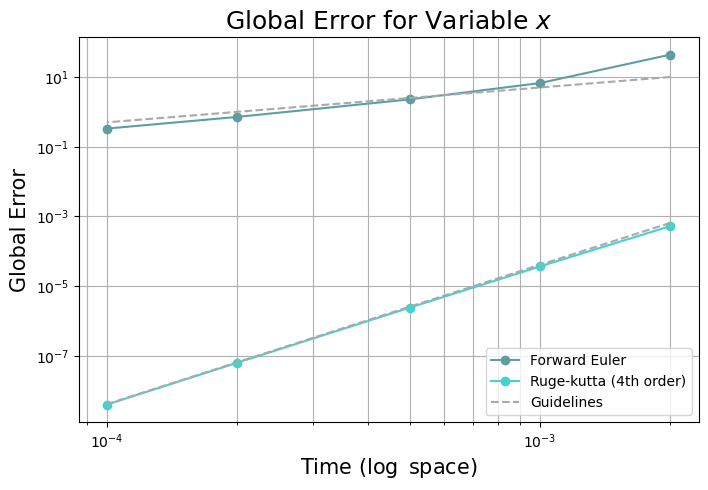

In [9]:
# Task 2.3

# Forward Euler method (taken from lab 2)
def ode_Euler(func, times, y0):
    '''
    integrates the system of y' = func(y, t) using forward Euler method
    for the time steps in times and given initial condition y0
    ----------------------------------------------------------
    inputs:
        func: the RHS function in the system of ODE
        times: the points in time (or the span of independent variable in ODE)
        y0: initial condition (make sure the dimension of y0 and func are the same)
    output:
        y: the solution of ODE. 
        Each row in the solution array y corresponds to a value returned in column vector t
    '''
    times = np.array(times)
    y0 = np.array(y0)
    n = y0.size       # the dimension of ODE 
    nT = times.size   # the number of time steps 
    y = np.zeros([nT,n])
    y[0, :] = y0
    # loop for timesteps
    for k in range(nT - 1):
        y[k+1, :] = y[k, :] + (times[k+1] - times[k]) * func(y[k, :], times[k])
    return y

# Ruge-kutta (4th order) method (taken from lab 2)
def ode_RK4(func, times, y0):
    '''
    integrates the system of y' = func(y, t) using Runge-Kutta 4th order
    for the time steps in times and given initial condition y0
    ----------------------------------------------------------
    inputs:
        func: the RHS function in the system of ODE
        times: the points in time (or the span of independent variable in ODE)
        y0: initial condition (make sure the dimension of y0 and func are the same)
    output:
        y: the solution of ODE. 
        Each row in the solution array y corresponds to a value returned in column vector t
    '''
    times = np.array(times)
    y0 = np.array(y0)
    n = y0.size       # the dimension of ODE 
    nT = times.size   # the number of time steps 
    y = np.zeros([nT,n])
    y[0, :] = y0
    for k in range(nT-1):
        dt = times[k+1] - times[k]
        f1 = func(y[k,:], times[k])
        f2 = func(y[k,:] + 0.5*dt*f1, times[k] + 0.5*dt)
        f3 = func(y[k,:] + 0.5*dt*f2, times[k] + 0.5*dt)
        f4 = func(y[k,:] + dt*f3, times[k] + dt)
        y[k+1,:] = y[k,:]+dt/6*(f1+2*f2+2*f3+f4)
    return y 

# Seting up initial conditions as x(0) = y(0) = z(0) = 100
X0_2 = [100, 100, 100]    

# Solve ODE with Ruge-kutta (order 4)
# Setting time step to h=10^{-6} (accurate enought, can be considered exact)
times_RK4 = np.linspace(0,0.3,300001)
exact = ode_RK4(dX_dt, times_RK4, X0_2)

# Solve ODE with Forward Euler
# Timesteps to investigate
timesteps = [0.002, 0.001, .0005, 0.0002, 0.0001]

errors_FE = []
errors_RK = []

for k in timesteps:
    t = int(0.3/k) + 1
    times = np.linspace(0,0.3,t)
    ode_FE = ode_Euler(dX_dt, times, X0_2)
    ode_RK = ode_RK4(dX_dt, times, X0_2)
    
    # Global error defined as |Euler(end_time) - exact(end_time)|
    global_error_FE = abs(ode_FE[-1,0] - exact[-1,0])
    errors_FE.append(global_error_FE)
    
    # Global error defined as |RK4(end_time) - exact(end_time)|
    global_error_RK = abs(ode_RK[-1,0] - exact[-1,0])
    errors_RK.append(global_error_RK)

# Plotting the global errors for both methods
fig, ax1 = plt.subplots(figsize=(8,5))
ax1.loglog(timesteps, errors_FE, "cadetblue", label = "Forward Euler", marker = 'o')
ax1.loglog(timesteps, errors_RK, "mediumturquoise", label = "Ruge-kutta (4th order)", marker = 'o')


# Adding guidelines

# Guideline for Ruge-Kutta (4th order) method, with power 4
guidelines_1 = np.multiply(np.power(timesteps,4), 41000000)
ax1.loglog(timesteps, guidelines_1 , "darkgrey", linestyle = '--', label = "Guidelines")

# Guideline for Forward Euler method, with power 1
guidelines_2 = np.multiply(np.power(timesteps,1), 5000)
ax1.loglog(timesteps, guidelines_2 , "darkgrey", linestyle = '--') 

ax1.set(title='semilogx')
plt.title(r'Global Error for Variable $x$', fontsize = 18)
plt.xlabel(r'Time ($\log$ space)', fontsize = 15)
plt.ylabel(r'Global Error', fontsize = 15)
plt.legend()
ax1.grid()
ax1.grid(which="minor")

**Analysing plot of Global Error for Variable $x$**


Generally, we expect the error in an approximation to worsen as the degree of accuracy is reduced (timesteps broadend), this is a exponential relationship, thus utilizing a log scale for this investigation allows us to understand the global error instead a linear way and ultimetly infer slope values.

The guideline corresponding to method Ruge-Kutta order 4 (KR4) is drawn with $h=10^{-4}$, which means its slope is 4, since RK4 lies very close to its guideline we can conclude that this method has slope of global error 4 against timestep.

Similarly, the guideline corresponding to Forward Euler method is drawn with $h=10^{-1}$, which means the slope is 1. We see that Forward Euler method lies close to this guideline (though with slightly more dicrepencey that of RK4), we can conclude that Forward Euler slope of global error 1 against timestep.

These aproximated slopes of Forward Euler and RK4 are as expected. We know that the RK4 method works by using 4 terms to approximate whilst Forward Euler uses just 1, this corresponds to their global error and overall accuracy. 

Generally, we expect the error in an approximation to worsen as the degree of accuracy is reduced (timesteps broadend), this is a exponential relationship, thus utilizing a log scale for this investigation allows us to understand the global error instead a linear way and ultimetly infer slope values.


--------------------
### Case of chaotic behaviour and strange attractor


Consider the set of parameters $\sigma = 10$, $\beta = 8/3$ and $\rho = 28$ and stick to Runge-Kutta scheme with timestep of $h = 10^{-4}$ for this part. 

**Task 2.4 (2 marks)** Draw the three-dimensional phase portraits using $x = y = z = 1$ as initial condition. You can use the script below to plot 3D curves.


**Task 2.5 (3 marks)** Change the initial condition as $x = 1 + \epsilon, y = 1, z = 1$, where $\epsilon$ is $10^{-1}$, $10^{-5}$ and $10^{-12}$. Draw the phase portrait for each initial condition and compare it to what you got for Task 2.4. Do they look different? Representing the outputs of these new solutions (with new initial conditions) with $x_1$, $y_1$ and $z_1$ and the solution starting from $x = y = z = 1$ with $x^*$, $y^*$ and $z^*$, compute a measure of difference between these solutions given by
  
\begin{equation*}
\mathcal{e}(t) = \sqrt{(x^*(t) - x_1(t))^2 +  (y^*(t) - y_1(t))^2 + (z^*(t) - z_1(t))^2}.
\end{equation*}
  
Plot the time-series diagrams of $\mathcal{e}(t)$ for three different values of $\epsilon$. From the behaviour of $\mathcal{e}(t)$ answer the following questions:

- If two initial conditions are very close, do their corresponding trajectories stay close to each other in time? 

- Do you see an upper bound for $\mathcal{e}(t)$? What does this imply?
  
  
*The moral of the story is that the exact realisations (the "weather") can have sensitive dependence on initial conditions, and in reality errors always exist, so loss of accuracy in weather prediction is fairly rapid. However there are gross features that remain roughly invariant and can be described, for example the butterfly attractor that you see in your results (the "climate").*

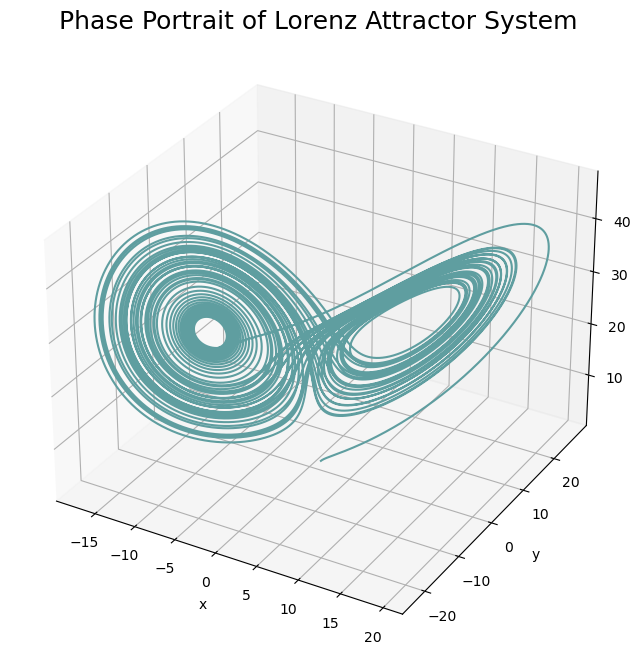

In [10]:
# Task 2.4

from mpl_toolkits.mplot3d import Axes3D

sigma2 = 10.0
beta2 = 8/3
rho2 = 28

# Defining the given Lorenz system of differential equations
def dX_dt2(X, t):
    x, y, z = X
    return np.array([-sigma2 * x + sigma2 * y, x * (rho2 - z) - y, x * y - beta2 * z])


# Seting up initial conditions as x(0) = y(0) = z(0) = 1
X0_3 = [1, 1, 1]    

# Solve ODE with Ruge-kutta (order 4)
# Setting time step to h=10^{-4}, from t = 1 to 20
times_RK4_3 = np.linspace(0,50,500000) 
ode_RK4_3 = ode_RK4(dX_dt2, times_RK4_3, X0_3)


# Plot
ax = plt.figure(figsize=(8,8)).add_subplot(projection='3d')
ax.set(xlabel='x', ylabel='y', zlabel='z')
ax.set_title("Phase Portrait of Lorenz Attractor System", fontsize = 18)
ax.plot(ode_RK4_3[:,0], ode_RK4_3[:,1], ode_RK4_3[:,2], 'cadetblue')
ax.set(xlabel='x', ylabel='y', zlabel='z')
plt.draw()
plt.show()

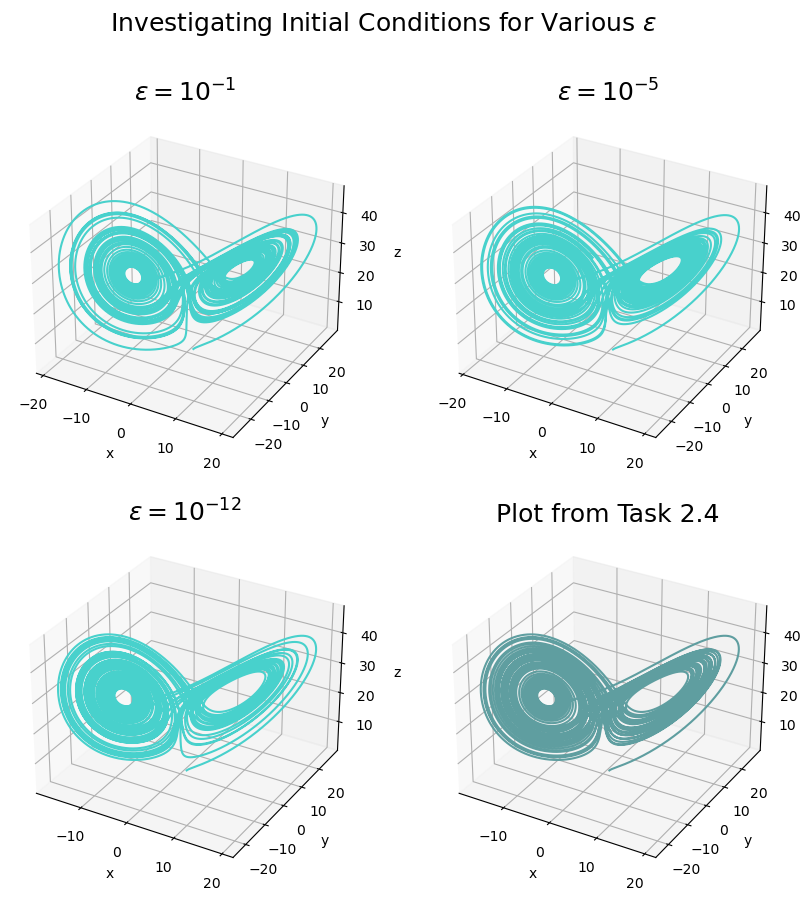

In [11]:
# Task 2.5

# Seting up initial conditions as x(0) = 1 + 𝜖 and y(0) = z(0) = 1

# Phase portrait 1 with 𝜖 = 10^-1
epsilon1 = 0.1
IC_1 = [1 + epsilon1, 1, 1] 

# Phase portrait 2 with 𝜖 = 10^-5
epsilon2 = 0.00001
IC_2 = [1 + epsilon2, 1, 1] 

# Phase portrait 3 with 𝜖 = 10^-12
epsilon3 = 0.000000000001
IC_3 = [1 + epsilon3, 1, 1] 
 

# Solve ODE with Ruge-kutta (order 4)
# Setting time step to h=10^{-4}
ode_RK4_IC_1 = ode_RK4(dX_dt2, times_RK4_3, IC_1)
ode_RK4_IC_2 = ode_RK4(dX_dt2, times_RK4_3, IC_2)
ode_RK4_IC_3 = ode_RK4(dX_dt2, times_RK4_3, IC_3)


# Plots
fig, axes = plt.subplots(2, 2 , figsize=(10,10), subplot_kw = {'projection': '3d'})
fig.suptitle(r'Investigating Initial Conditions for Various $\epsilon$', fontsize = 18)
axes = axes.flatten()

axes[0].plot(ode_RK4_IC_1[:,0], ode_RK4_IC_1[:,1], ode_RK4_IC_1[:,2], 'mediumturquoise')
axes[0].set_title(r'$\epsilon = 10^{-1}$', fontsize = 18)
axes[0].set(xlabel='x', ylabel='y', zlabel='z')

axes[1].plot(ode_RK4_IC_2[:,0], ode_RK4_IC_2[:,1], ode_RK4_IC_2[:,2], 'mediumturquoise')
axes[1].set_title(r'$\epsilon = 10^{-5}$', fontsize = 18)
axes[1].set(xlabel='x', ylabel='y', zlabel='z')

axes[2].plot(ode_RK4_IC_3[:,0], ode_RK4_IC_3[:,1], ode_RK4_IC_3[:,2], 'mediumturquoise')
axes[2].set_title(r'$\epsilon = 10^{-12}$', fontsize = 18)
axes[2].set(xlabel='x', ylabel='y', zlabel='z')

axes[3].plot(ode_RK4_3[:,0], ode_RK4_3[:,1], ode_RK4_3[:,2], 'cadetblue')
axes[3].set_title(r'Plot from Task 2.4', fontsize = 18)
axes[3].set(xlabel='x', ylabel='y', zlabel='z')

plt.draw()
plt.show()

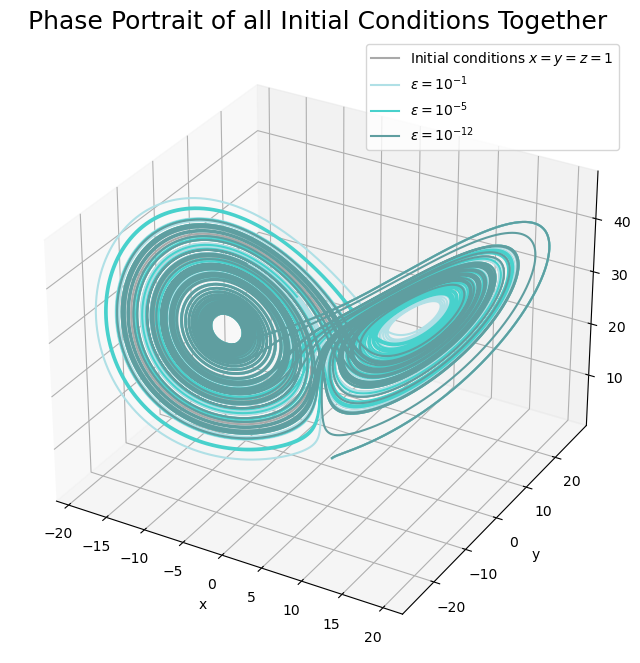

In [14]:
# Plotting the outcomes on one graph
ax = plt.figure(figsize=(8,8)).add_subplot(projection='3d')
ax.set(xlabel='x', ylabel='y', zlabel='z')
ax.set_title("Phase Portrait of all Initial Conditions Together", fontsize = 18)
ax.plot(ode_RK4_3[:,0], ode_RK4_3[:,1], ode_RK4_3[:,2], 'darkgrey', label = r'Initial conditions $x=y=z=1$')
ax.plot(ode_RK4_IC_1[:,0], ode_RK4_IC_1[:,1], ode_RK4_IC_1[:,2], 'powderblue', label = r'$\epsilon = 10^{-1}$')
ax.plot(ode_RK4_IC_2[:,0], ode_RK4_IC_2[:,1], ode_RK4_IC_2[:,2], 'mediumturquoise', label = r'$\epsilon = 10^{-5}$')
ax.plot(ode_RK4_IC_3[:,0], ode_RK4_IC_3[:,1], ode_RK4_IC_3[:,2], 'cadetblue', label = r'$\epsilon = 10^{-12}$')
ax.set(xlabel='x', ylabel='y', zlabel='z')
plt.legend()
plt.draw()
plt.show()


**Comparison with plot in Task 2.4**


The phase portrait for initial conditions $x = y = z = 1$ acheives this butterfly attractor shape. In the other phase portraits we see that by altering the initial conditions by $\epsilon$ results in changes to the resulting attractor shape.

In the phase portrait for $\epsilon=10^{-1}$, we see the most deviation from that of initial conditions $x = y = z = 1$ phase portrait. Since this value of $\epsilon$ it the largest difference we investigate, we expect there to be the most difference in this phase portrait.

For the phase portraits using $\epsilon=10^{-5}$ and $\epsilon=10^{-12}$, there is still subtle deviation from that of initial conditions $x = y = z = 1$ phase portrait. We expect that the smallest discrepency in $\epsilon$ will result in the most comparable phase portraits. 

The conclusion that can be drawn from these plots is that there is a sensitive dependence on initial conditions. 



-------------

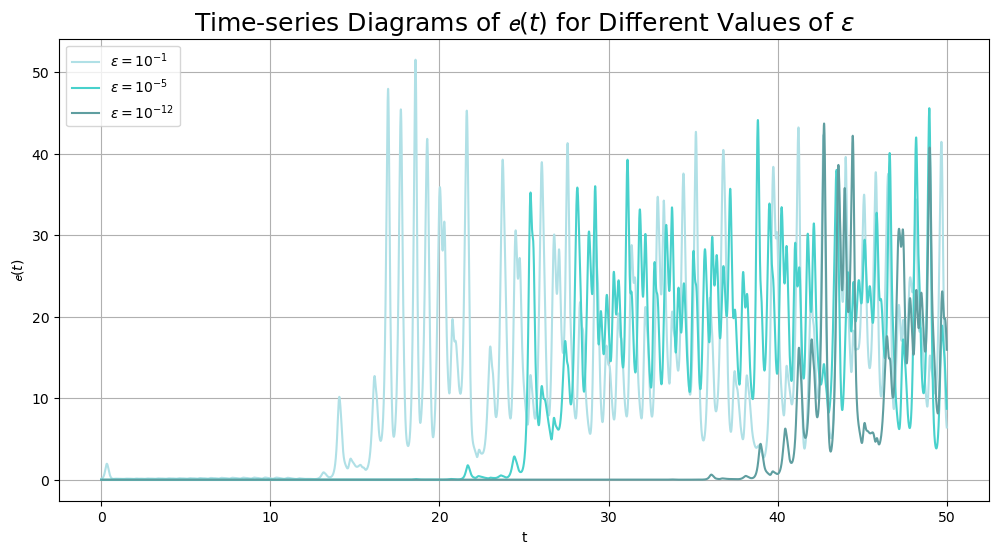

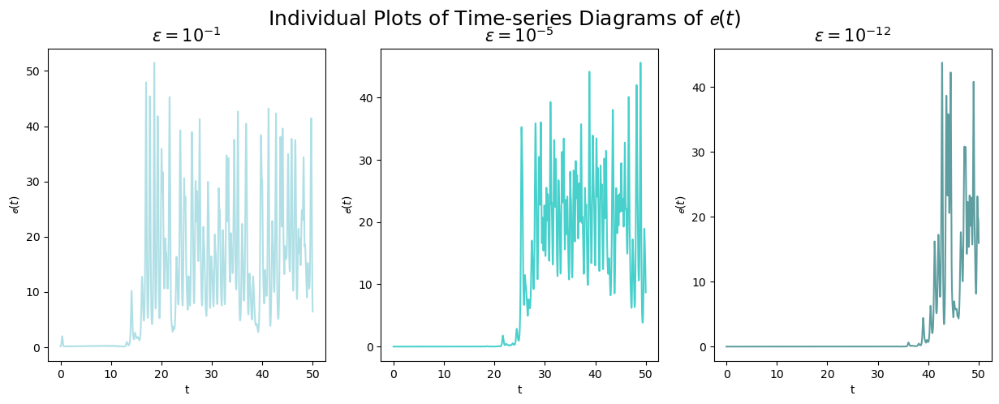

In [13]:
# Plot the time-series diagrams of e(𝑡)

# for 𝜖 = 10^-1
et_1 = np.sqrt((ode_RK4_3[:,0] - ode_RK4_IC_1[:,0]) ** 2 +
              (ode_RK4_3[:,1] - ode_RK4_IC_1[:,1]) ** 2 +
              (ode_RK4_3[:,2] - ode_RK4_IC_1[:,2]) ** 2)

# for 𝜖 = 10^-5
et_2 = np.sqrt((ode_RK4_3[:,0] - ode_RK4_IC_2[:,0]) ** 2 +
              (ode_RK4_3[:,1] - ode_RK4_IC_2[:,1]) ** 2 +
              (ode_RK4_3[:,2] - ode_RK4_IC_2[:,2]) ** 2)

# for 𝜖 = 10^-12
et_3 = np.sqrt((ode_RK4_3[:,0] - ode_RK4_IC_3[:,0]) ** 2 +
              (ode_RK4_3[:,1] - ode_RK4_IC_3[:,1]) ** 2 +
              (ode_RK4_3[:,2] - ode_RK4_IC_3[:,2]) ** 2)

# Plots
plt.figure(figsize=(12,6))
plt.plot(times_RK4_3, et_1, label=r'$\epsilon = 10^{-1}$', color = "powderblue")
plt.plot(times_RK4_3, et_2, label=r'$\epsilon = 10^{-5}$', color = "mediumturquoise")
plt.plot(times_RK4_3, et_3, label=r'$\epsilon = 10^{-12}$', color = "cadetblue")

plt.title(r'Time-series Diagrams of $\mathcal{e}(t)$ for Different Values of $\epsilon$', fontsize = 18)
plt.xlabel('t')
plt.ylabel(r'$\mathcal{e}(t)$')
plt.legend()
plt.grid(True)
plt.show()

# Individual plots
fig, axs = plt.subplots(1, 3, figsize=(15,5))
fig.suptitle('Individual Plots of Time-series Diagrams of $\mathcal{e}(t)$', fontsize = 18)
axs[0].plot(times_RK4_3, et_1, color = "powderblue")
axs[0].set_title(r'$\epsilon = 10^{-1}$', fontsize = 15)
axs[0].set(xlabel='t', ylabel=r'$\mathcal{e}(t)$')

axs[1].plot(times_RK4_3, et_2, color = "mediumturquoise")
axs[1].set_title('$\epsilon = 10^{-5}$', fontsize = 15)
axs[1].set(xlabel='t', ylabel=r'$\mathcal{e}(t)$')

axs[2].plot(times_RK4_3, et_3, color = "cadetblue")
axs[2].set_title(r'$\epsilon = 10^{-12}$', fontsize = 15)
axs[2].set(xlabel='t', ylabel=r'$\mathcal{e}(t)$');

**If two initial conditions are very close, do their corresponding trajectories stay close to each other in time?**


We see that as the value of $\epsilon$ gets smaller (or closer to the initial conditions $x=y=z=1$) we have that $\mathcal{e}(t)$ only begins to spike later in time. 

For $\epsilon=10^{-1}$ we see that there is very rapidly difference between the initial conditions $x=y=z=1$, the value of $\mathcal{e}(t)$ here becomes eratic from as early as approximately $t=12$. This is to be expected, since this is the inital condition furthest from $x=y=z=1$, we would expect the difference between outcomes to present the most difference. 

For the $\mathcal{e}(t)$ seen when $\epsilon=10^{-5}$, there is slightly more time when it behaves as $x=y=z=1$ does, we have here that the solution only begins to become different at approximatley $t=20$. 

Then observing the plot for $\epsilon=10^{-12}$, we see the longest duration for which it behaves like $x=y=z=1$. It behaves the same for approximately $t=35$, a far better result than that of $\epsilon=10^{-1}$ and $\epsilon=10^{-5}$. 

The results of the $\mathcal{e}(t)$ plots tell us that as initial conditions get closer to one another their resulting trajectories stay close to each other. This again reinforces the result from our 3d plots previously, that initial conditions are extreamly sensitive.

**Do you see an upper bound for $\mathcal{e}(t)$? What does this imply?**


Our plots do suggest that there is an upper bound for $\mathcal{e}(t)$. We see that for each $\epsilon$, the largest $\mathcal{e}(t)$ reaches is approximately 50. This implies that once a trajectory is within a certain distance from critical points it it will only differ by an certain amount of error. Our system with its inital conditions produce this butterfly attractor pattern, once trajectories are within the range of this pattern (near critical points) it will remain in this area indefinetly, and so can only differ by a set amount from the trajectory of initial condition $x=y=z=1$. Hence $\mathcal{e}(t)$ has an upper bound.



-----------------------